# Лабораторная работа № 1  
## Анализ и прогнозирование временных рядов на примере розничных продаж

Структура работы:

1. Загрузка данных и проверка качества.
2. Разведочный анализ данных, визуализация.
3. Декомпозиция ряда:
   - классическая аддитивная;
   - классическая мультипликативная;
   - STL-декомпозиция.
4. Спектральный анализ с помощью быстрого преобразования Фурье, FFT.
5. Вейвлет-анализ с использованием вейвлета Морле.
6. Построение прогнозных моделей `ARIMA` и `SARIMAX`.
7. Оценка качества моделей: `MSE`, `R²`, `AIC`, `BIC`.
8. Диагностика остатков: нормальность, автокорреляция, гомоскедастичность, ARCH-эффекты.
9. Финальный прогноз на 12 месяцев.


## 0. Импорт библиотек и загрузка данных

На защите важно показать, что данные не берутся из головы и не подменяются встроенным примером. Поэтому импорт выполняется только из файла, лежащего рядом с ноутбуком.

Проверяем:

1. Наличие файла в текущей директории.
2. Корректность даты.
3. Сортировку по времени.
4. Наличие дубликатов дат.
5. Приведение к месячной частоте.
6. Пропуски.


In [14]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan, het_arch
from scipy import stats
from scipy.signal import detrend, fftconvolve

plt.rcParams.update({
    'figure.figsize': (12, 4.2),
    'axes.grid': True,
    'grid.alpha': 0.3
})

DATA_CANDIDATES = [
    Path('retail_sales_mock_data.csv'),
    Path('retail_sales_mock_data')
]

data_path = next((p for p in DATA_CANDIDATES if p.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        'В текущей директории не найден файл retail_sales_mock_data.csv или retail_sales_mock_data. '
        'Положите файл данных рядом с ноутбуком.'
    )

df = pd.read_csv(data_path, parse_dates=['Date'], index_col='Date')
df = df.sort_index()

if df.index.duplicated().any():
    print('Найдены дубликаты дат. Оставляем последнее значение для каждой даты.')
    df = df[~df.index.duplicated(keep='last')]

df = df.asfreq('MS')

if df['SalesAmount'].isna().any():
    print('После приведения к частоте есть пропуски. Заполняем их интерполяцией по времени.')
    df['SalesAmount'] = df['SalesAmount'].interpolate(method='time').limit_direction('both')

y = df['SalesAmount'].astype(float)

print(f'Файл данных: {data_path}')
print(f'Количество наблюдений: {len(y)}')
print(f'Период: {y.index.min().date()} — {y.index.max().date()}')
print(f'Пропуски: {df.isna().sum().to_dict()}')

display(df.head())
display(df.describe().round(2))


Файл данных: retail_sales_mock_data.csv
Количество наблюдений: 48
Период: 2020-01-01 — 2023-12-01
Пропуски: {'SalesAmount': 0, 'Promotion': 0, 'HolidayMonth': 0}


,SalesAmount,Promotion,HolidayMonth
Date,,,
2020-01-01,12248,0,0
2020-02-01,13011,0,0
2020-03-01,12722,0,0
2020-04-01,14030,1,0
2020-05-01,7783,0,0


,SalesAmount,Promotion,HolidayMonth
count,48.00,48.00,48.00
mean,11768.54,0.12,0.08
std,2257.54,0.33,0.28
min,7783.00,0.00,0.00
25%,10219.75,0.00,0.00
50%,11851.00,0.00,0.00
75%,13014.00,0.00,0.00
max,17996.00,1.00,1.00


## 1. Разведочный анализ данных, EDA

используем:

- исходный ряд;
- скользящие средние;
- скользящее стандартное отклонение;
- гистограмму;
- боксплоты по месяцам;
- тепловую карту «год × месяц»;
- тест Дики-Фуллера на стационарность.


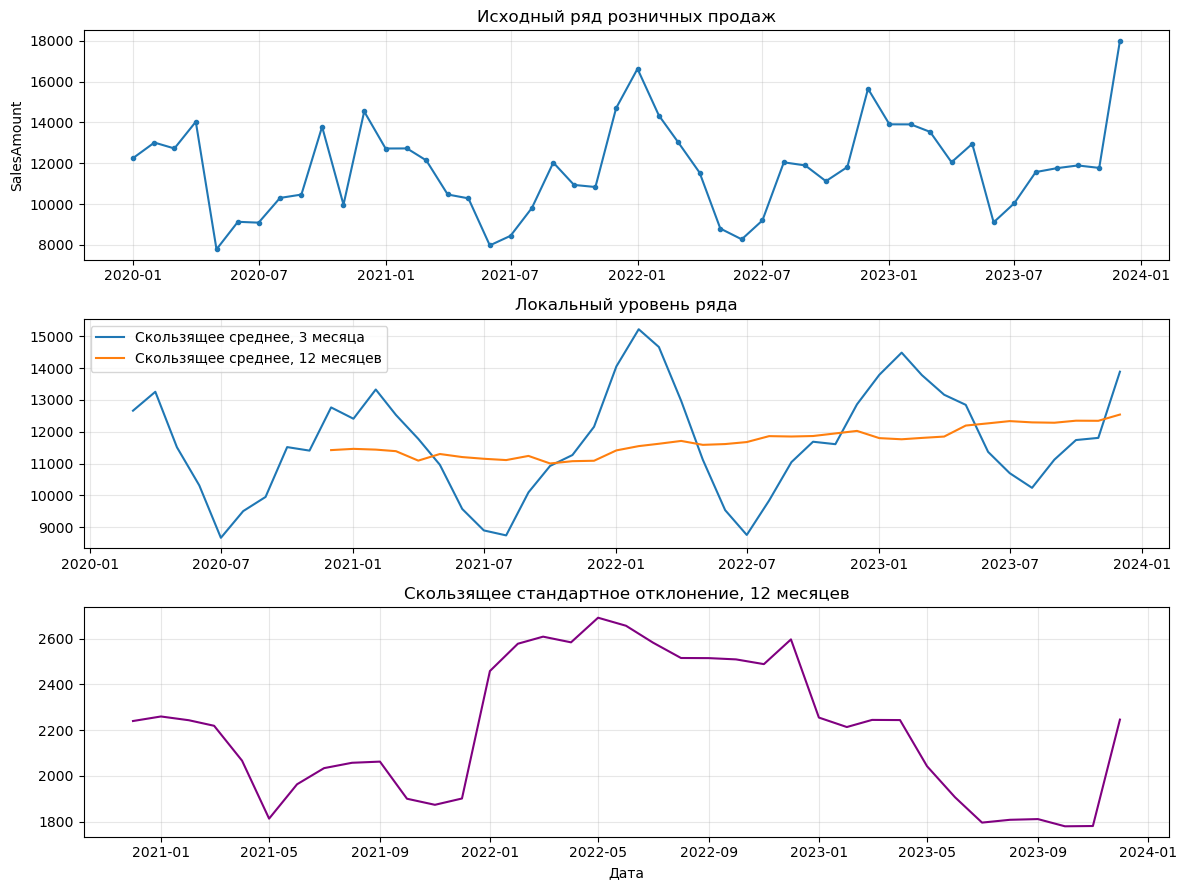

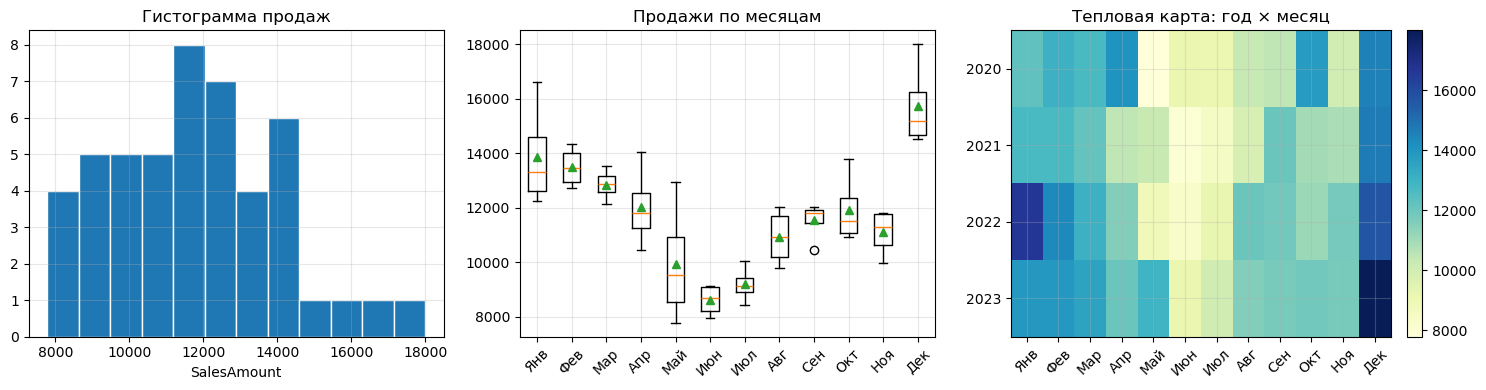

Среднее: 11768.5
Стандартное отклонение: 2257.5
Коэффициент вариации, %: 19.2
Минимум: 2020-05-01 7783.0
Максимум: 2023-12-01 17996.0


,Ряд,ADF,p-value,Лагов,Вывод
0,Уровни ряда,-4.5142,0.0002,5,стационарен при 5%
1,Разность 1-го порядка,-5.6296,0.0000,10,стационарен при 5%
2,Сезонная разность 12,-3.6261,0.0053,3,стационарен при 5%


In [15]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9))

axes[0].plot(y, marker='o', ms=3)
axes[0].set_title('Исходный ряд розничных продаж')
axes[0].set_ylabel('SalesAmount')

axes[1].plot(y.rolling(3).mean(), label='Скользящее среднее, 3 месяца')
axes[1].plot(y.rolling(12).mean(), label='Скользящее среднее, 12 месяцев')
axes[1].set_title('Локальный уровень ряда')
axes[1].legend()

axes[2].plot(y.rolling(12).std(), color='purple')
axes[2].set_title('Скользящее стандартное отклонение, 12 месяцев')
axes[2].set_xlabel('Дата')

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(y, bins=12, edgecolor='white')
axes[0].set_title('Гистограмма продаж')
axes[0].set_xlabel('SalesAmount')

month_names = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн',
               'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']

data_by_month = [y[y.index.month == m].values for m in range(1, 13)]
bp = axes[1].boxplot(data_by_month, showmeans=True)
axes[1].set_xticklabels(month_names, rotation=45)
axes[1].set_title('Продажи по месяцам')

pivot = y.to_frame('SalesAmount')
pivot['Year'] = pivot.index.year
pivot['Month'] = pivot.index.month
heat = pivot.pivot(index='Year', columns='Month', values='SalesAmount')

im = axes[2].imshow(heat.values, aspect='auto', cmap='YlGnBu')
axes[2].set_xticks(range(len(month_names)))
axes[2].set_xticklabels(month_names, rotation=45)
axes[2].set_yticks(range(len(heat.index)))
axes[2].set_yticklabels(heat.index)
axes[2].set_title('Тепловая карта: год × месяц')
fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

print('Среднее:', round(y.mean(), 1))
print('Стандартное отклонение:', round(y.std(), 1))
print('Коэффициент вариации, %:', round(100 * y.std() / y.mean(), 1))
print('Минимум:', y.idxmin().date(), y.min())
print('Максимум:', y.idxmax().date(), y.max())

def adf_report(name, series):
    s = series.dropna()
    result = adfuller(s, autolag='AIC')
    return {
        'Ряд': name,
        'ADF': result[0],
        'p-value': result[1],
        'Лагов': result[2],
        'Вывод': 'стационарен при 5%' if result[1] < 0.05 else 'не отвергаем единичный корень'
    }

adf_table = pd.DataFrame([
    adf_report('Уровни ряда', y),
    adf_report('Разность 1-го порядка', y.diff()),
    adf_report('Сезонная разность 12', y.diff(12))
])

display(adf_table.round(4))


### Вывод по первичному анализу

Смотрим сразу несколько артефактов:

1. Если скользящее среднее изменяется во времени, это признак тренда.
2. Если скользящее стандартное отклонение сильно растёт, это признак нестабильной дисперсии.
3. Боксплоты по месяцам показывают, какие месяцы систематически выше или ниже.
4. Тепловая карта позволяет увидеть повторяющуюся годовую структуру.
5. Тест Дики-Фуллера нужен для проверки стационарности. Если уровни ряда нестационарны, но разности стационарны, это обосновывает использование дифференцирования в `ARIMA`/`SARIMAX`.


## 2. Декомпозиция временного ряда

Декомпозиция нужна, чтобы разделить ряд на компоненты:

- тренд
- сезонность
- остаток

Используем три подхода:

1. Классическая аддитивная декомпозиция.  
   Подходит, если сезонные колебания примерно постоянны по абсолютной величине.

2. Классическая мультипликативная декомпозиция.  
   Подходит, если амплитуда сезонности растёт вместе с уровнем ряда.

3. `STL`-декомпозиция.  
   Более устойчивый метод, допускает робастную оценку и лучше работает с выбросами.


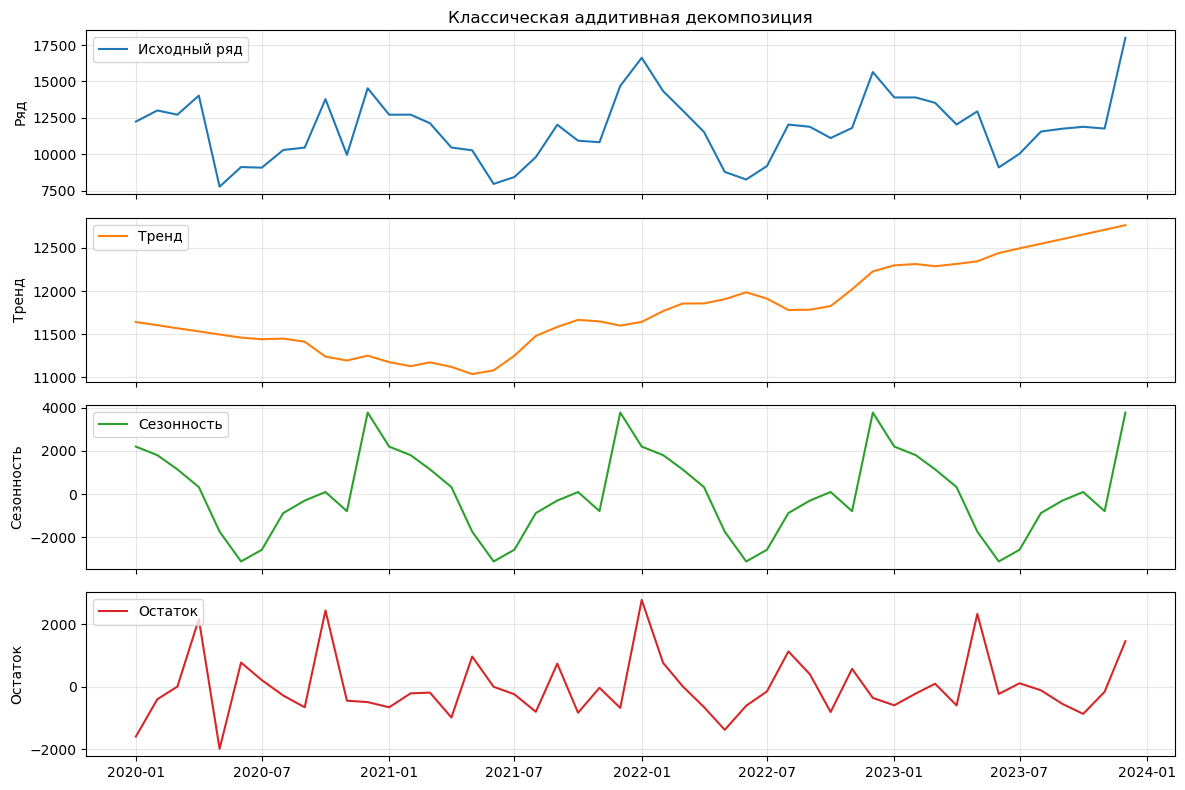

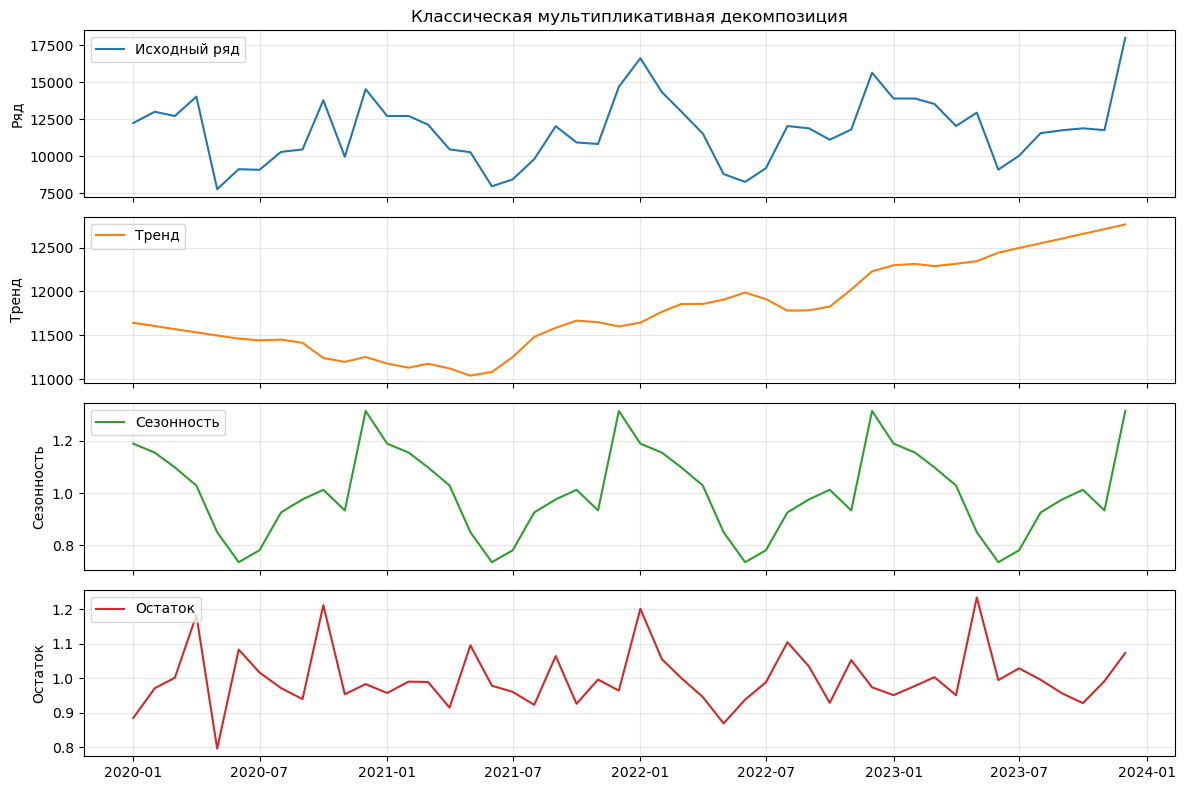

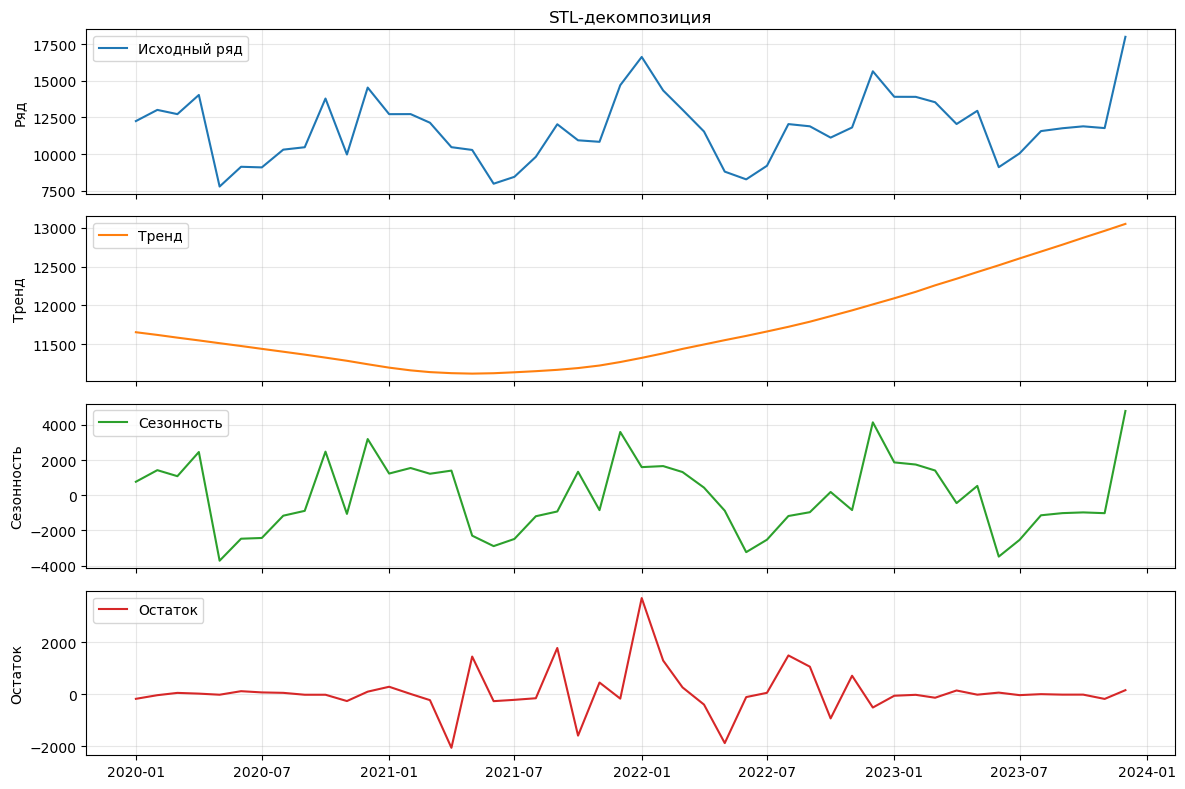

Сезонный профиль по месяцам:


Date
1     1364.5
2     1592.1
3     1255.7
4      960.1
5    -1588.8
6    -3016.1
7    -2490.8
8    -1166.9
9     -946.0
10     754.8
11    -940.5
12    3925.5
Name: season, dtype: float64

Амплитуда сезонного профиля, max - min: 6941.5
Сила сезонности: 0.839
Сила тренда: 0.257


In [16]:
PERIOD = 12

def plot_decomposition(result, title, original):
    fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)

    axes[0].plot(original, label='Исходный ряд')
    axes[1].plot(result.trend, color='tab:orange', label='Тренд')
    axes[2].plot(result.seasonal, color='tab:green', label='Сезонность')
    axes[3].plot(result.resid, color='tab:red', label='Остаток')

    for ax, name in zip(axes, ['Ряд', 'Тренд', 'Сезонность', 'Остаток']):
        ax.set_ylabel(name)
        ax.legend(loc='upper left')

    axes[0].set_title(title)
    plt.tight_layout()
    plt.show()

add_dec = seasonal_decompose(y, model='additive', period=PERIOD, extrapolate_trend='freq')
mul_dec = seasonal_decompose(y, model='multiplicative', period=PERIOD, extrapolate_trend='freq')
stl_dec = STL(y, period=PERIOD, robust=True).fit()

plot_decomposition(add_dec, 'Классическая аддитивная декомпозиция', y)
plot_decomposition(mul_dec, 'Классическая мультипликативная декомпозиция', y)
plot_decomposition(stl_dec, 'STL-декомпозиция', y)

seasonal_profile = stl_dec.seasonal.groupby(stl_dec.seasonal.index.month).mean()

print('Сезонный профиль по месяцам:')
display(seasonal_profile.round(1))

print('Амплитуда сезонного профиля, max - min:',
      round(seasonal_profile.max() - seasonal_profile.min(), 1))

var_resid = np.var(stl_dec.resid)
season_strength = max(0.0, 1.0 - var_resid / np.var(stl_dec.resid + stl_dec.seasonal))
trend_strength = max(0.0, 1.0 - var_resid / np.var(stl_dec.resid + stl_dec.trend))

print(f'Сила сезонности: {season_strength:.3f}')
print(f'Сила тренда: {trend_strength:.3f}')


### Вывод по декомпозиции

1. Аддитивная модель предполагает, что сезонность складывается с трендом в абсолютных единицах.
2. Мультипликативная модель предполагает, что сезонность масштабирует уровень ряда.
3. `STL` нужен как контрольный, более устойчивый вариант, потому что он меньше страдает от выбросов и позволяет лучше отделить сезонную компоненту от шума.


## 3. Спектральный анализ: быстрое преобразование Фурье, FFT

FFT переводит сигнал из временной области в частотную. Это нужно, чтобы проверить, есть ли в ряде устойчивые периодические составляющие.

Главный проверяемый период 12 месяцев, потому что данные месячные и ожидается годовая сезонность.


перед FFT убираем линейный тренд, чтобы тренд не маскировал периодические компоненты;
смотрим не только график, но и таблицу периодов с наибольшей мощностью.


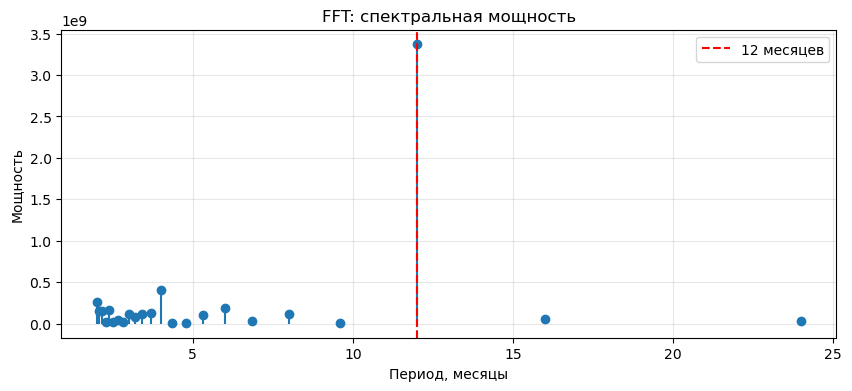

,"Период, мес.",Мощность
2,12.0,3.376921e+09
10,4.0,4.068245e+08
22,2.0,2.581354e+08
6,6.0,1.891419e+08
18,2.4,1.650044e+08


In [17]:
x = detrend(y.values, type='linear')

freqs = np.fft.rfftfreq(len(x), d=1.0)
power = np.abs(np.fft.rfft(x)) ** 2

mask = freqs > 0
periods = 1.0 / freqs[mask]
power_pos = power[mask]

plot_mask = (periods >= 2) & (periods <= 24)

plt.figure(figsize=(10, 4))
plt.stem(periods[plot_mask], power_pos[plot_mask], basefmt=' ')
plt.axvline(12, color='red', linestyle='--', label='12 месяцев')
plt.title('FFT: спектральная мощность')
plt.xlabel('Период, месяцы')
plt.ylabel('Мощность')
plt.legend()
plt.show()

fft_table = pd.DataFrame({
    'Период, мес.': periods[plot_mask],
    'Мощность': power_pos[plot_mask]
})

fft_table = fft_table.sort_values('Мощность', ascending=False).head(5)
display(fft_table.round(3))


### Вывод по FFT

Если наибольшая мощность сосредоточена около периода 12 месяцев, это подтверждает годовую сезонность.

Ограничение метода:

- FFT предполагает, что периодичности глобальны и устойчивы на всём отрезке времени;
- метод плохо показывает, если сезонность меняет амплитуду или фазу во времени.

Поэтому далее нужен вейвлет-анализ.


## 4. Вейвлет-анализ: вейвлет Морле

Вейвлет-анализ показывает не только какие периоды присутствуют, но и когда они проявляются. Это временно-частотное представление.


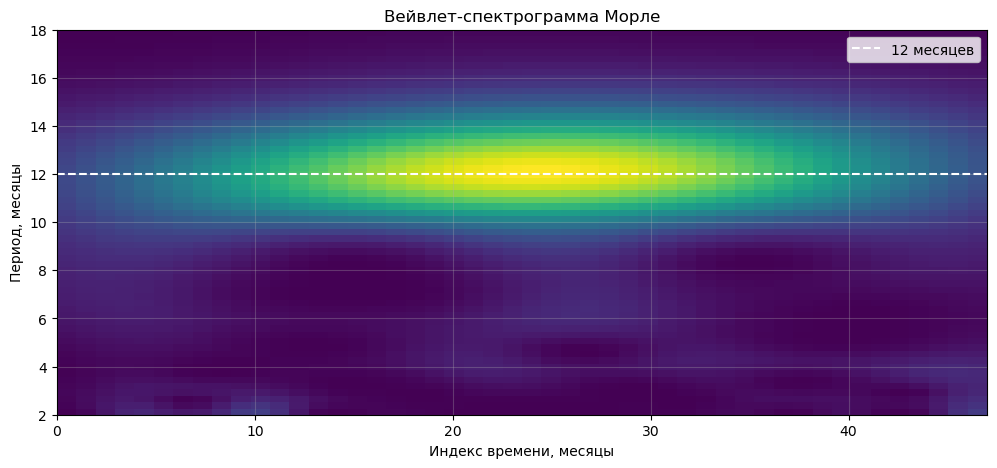

In [18]:
def morlet_cwt(values, periods, omega0=6.0):
    x = np.asarray(values, dtype=float)
    x = x - np.mean(x)

    coefficients = np.empty((len(periods), len(x)), dtype=complex)

    for i, period in enumerate(periods):
        scale = float(period) * omega0 / (2.0 * np.pi)
        extent = int(np.ceil(4.0 * scale))
        u = np.arange(-extent, extent + 1) / scale
        wave = np.exp(1j * omega0 * u) * np.exp(-0.5 * u * u)
        wave /= np.sqrt(scale)

        coefficients[i] = fftconvolve(x, np.conj(wave[::-1]), mode='same')

    return coefficients

wavelet_periods = np.linspace(2, 18, 60)
cwt_coeff = morlet_cwt(detrend(y.values, type='linear'), wavelet_periods)
cwt_power = np.abs(cwt_coeff) ** 2

plt.figure(figsize=(12, 5))
plt.imshow(
    cwt_power,
    aspect='auto',
    origin='lower',
    cmap='viridis',
    extent=[0, len(y) - 1, wavelet_periods.min(), wavelet_periods.max()]
)
plt.axhline(12, color='white', linestyle='--', label='12 месяцев')
plt.title('Вейвлет-спектрограмма Морле')
plt.xlabel('Индекс времени, месяцы')
plt.ylabel('Период, месяцы')
plt.legend()
plt.show()


### Сравнение трёх методов декомпозиции и анализа периодичности

| Метод | Что показывает | Преимущества | Ограничения |
|---|---|---|---|
| Классическая аддитивная/мультипликативная декомпозиция | Тренд, сезонность, остаток | Простота, наглядность, понятная интерпретация | Плохо работает с меняющейся сезонностью и выбросами |
| `STL` | Более устойчивая декомпозиция | Робастность, лучше отделяет шум | Сложнее интерпретация, чем у классической декомпозиции |
| `FFT` | Глобальные частоты | Хорошо находит устойчивые периоды | Не показывает время появления периодичности |
| Вейвлет Морле | Периодичность во времени | Показывает изменение сезонности во времени | Требует аккуратной интерпретации мощности |

Ни один метод не является достаточным сам по себе. Поэтому используется несколько подходов: декомпозиция показывает структуру, `FFT` проверяет наличие периода 12 месяцев, вейвлет проверяет устойчивость этой сезонности во времени.


## 5. Подготовка к моделированию: разбиение на выборки

Нельзя обучать модель на всех данных и сразу заявлять, что она хорошо прогнозирует. Нужна честная проверка на периодах, которые модель не видела.

Используем временное разбиение без перемешивания:

- `train` — обучение;
- `valid` — валидация для выбора модели;
- `test` — финальная проверка качества.


In [19]:
if len(y) >= 36:
    train = y.iloc[:-24]
    valid = y.iloc[-24:-12]
    test = y.iloc[-12:]
else:
    train = y.iloc[:-12]
    valid = y.iloc[-12:]
    test = None

print('Train:', train.index.min().date(), '—', train.index.max().date(), '| длина:', len(train))
print('Valid:', valid.index.min().date(), '—', valid.index.max().date(), '| длина:', len(valid))

if test is not None:
    print('Test:', test.index.min().date(), '—', test.index.max().date(), '| длина:', len(test))


Train: 2020-01-01 — 2021-12-01 | длина: 24
Valid: 2022-01-01 — 2022-12-01 | длина: 12
Test: 2023-01-01 — 2023-12-01 | длина: 12


## 6. Признаки для сезонных моделей

В прогнозировании нельзя использовать признаки, которые неизвестны на момент прогноза.

Например:

- `Promotion` в общем случае нельзя использовать для будущего прогноза, потому что будущие промо-акции могут быть неизвестны;
- календарный признак «декабрь» использовать можно, потому что месяц будущего года известен заранее;
- фурье-компоненты тоже можно использовать, потому что они являются детерминированной функцией месяца.

Поэтому для части моделей `SARIMAX` создаём:

- синусы и косинусы для годовой сезонности;
- индикатор декабря.


In [20]:
def calendar_features(index, K=2):
    index = pd.DatetimeIndex(index)
    out = pd.DataFrame(index=index)

    month = index.month.values.astype(float)

    for k in range(1, K + 1):
        angle = 2.0 * np.pi * k * (month - 1.0) / 12.0
        out[f'sin_{k}'] = np.sin(angle)
        out[f'cos_{k}'] = np.cos(angle)

    out['December'] = (index.month == 12).astype(float)
    return out

FOURIER_COLS = [f'{func}_{k}' for k in range(1, 3) for func in ['sin', 'cos']]

def get_exog(exog_type, index):
    if exog_type is None:
        return None

    feats = calendar_features(index)

    if exog_type == 'fourier':
        return feats[FOURIER_COLS]

    if exog_type == 'fourier_dec':
        return feats[FOURIER_COLS + ['December']]

    raise ValueError(f'Неизвестный тип экзогенных признаков: {exog_type}')

MODEL_CONFIGS = {
    'ARIMA(2,1,1)': {
        'family': 'ARIMA',
        'order': (2, 1, 1),
        'seasonal_order': None,
        'exog': None,
        'trend': 'c'
    },
    'SARIMAX(0,1,1)x(0,1,0,12)': {
        'family': 'SARIMAX',
        'order': (0, 1, 1),
        'seasonal_order': (0, 1, 0, 12),
        'exog': None,
        'trend': None
    },
    'SARIMAX(1,0,0)x(0,1,0,12)': {
        'family': 'SARIMAX',
        'order': (1, 0, 0),
        'seasonal_order': (0, 1, 0, 12),
        'exog': None,
        'trend': 'c'
    },
    'SARIMAX Fourier K=2': {
        'family': 'SARIMAX',
        'order': (1, 0, 0),
        'seasonal_order': (0, 0, 0, 12),
        'exog': 'fourier',
        'trend': 'c'
    },
    'SARIMAX Fourier+December': {
        'family': 'SARIMAX',
        'order': (1, 0, 0),
        'seasonal_order': (0, 0, 0, 12),
        'exog': 'fourier_dec',
        'trend': 'c'
    }
}

def fit_model(name, target):
    cfg = MODEL_CONFIGS[name]
    exog = get_exog(cfg['exog'], target.index)

    if cfg['family'] == 'ARIMA':
        model = ARIMA(
            target,
            order=cfg['order'],
            trend=cfg['trend'],
            enforce_stationarity=False,
            enforce_invertibility=False
        )
        return model.fit()

    model = SARIMAX(
        target,
        order=cfg['order'],
        seasonal_order=cfg['seasonal_order'],
        exog=exog,
        trend=cfg['trend'],
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    return model.fit(disp=False)

def forecast_model(name, fitted, index):
    cfg = MODEL_CONFIGS[name]
    exog = get_exog(cfg['exog'], index)

    fc = fitted.get_forecast(steps=len(index), exog=exog)

    pred = pd.Series(np.asarray(fc.predicted_mean), index=index, name=name)
    ci = np.asarray(fc.conf_int(alpha=0.05))
    ci = pd.DataFrame(ci, index=index, columns=['lower', 'upper'])

    return pred, ci

def mse(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    return float(np.mean((actual - predicted) ** 2))

def r2(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    ss_res = np.sum((actual - predicted) ** 2)
    ss_tot = np.sum((actual - np.mean(actual)) ** 2)

    if ss_tot == 0:
        return np.nan

    return float(1.0 - ss_res / ss_tot)


## 7. Выбор модели на валидации

Сначала обучаем модели только на `train` и проверяем качество на `valid`.

Метрики:

- `MSE` — штрафует большие ошибки;
- `R²` — показывает, насколько модель лучше простого прогноза средним;
- `AIC` и `BIC` — используются для сравнения качества подгонки, но их нельзя абсолютизировать, если модели имеют разные порядки дифференцирования или разные эффективные выборки.

Выбор модели делаем по минимальной `MSE` на валидации, потому что для прогнозной задачи важнее ошибка прогноза, чем только качество подгонки.


Модель ARIMA(2,1,1) не обучилась: ValueError: In models with integration (`d > 0`) or seasonal integration (`D > 0`), trend terms of lower order than `d + D` cannot be (as they would be eliminated due to the differencing operation). For example, a constant cannot be included in an ARIMA(1, 1, 1) model, but including a linear trend, which would have the same effect as fitting a constant to the differenced data, is allowed.


,Модель,MSE validation,R2 validation,AIC train,BIC train
0,"SARIMAX(0,1,1)x(0,1,0,12)",2.568520e+06,0.584,170.026,170.420
1,SARIMAX Fourier K=2,3.346704e+06,0.459,397.854,405.802
2,"SARIMAX(1,0,0)x(0,1,0,12)",3.540356e+06,0.427,196.125,197.319
3,SARIMAX Fourier+December,1.412067e+07,-1.285,453.900,462.983


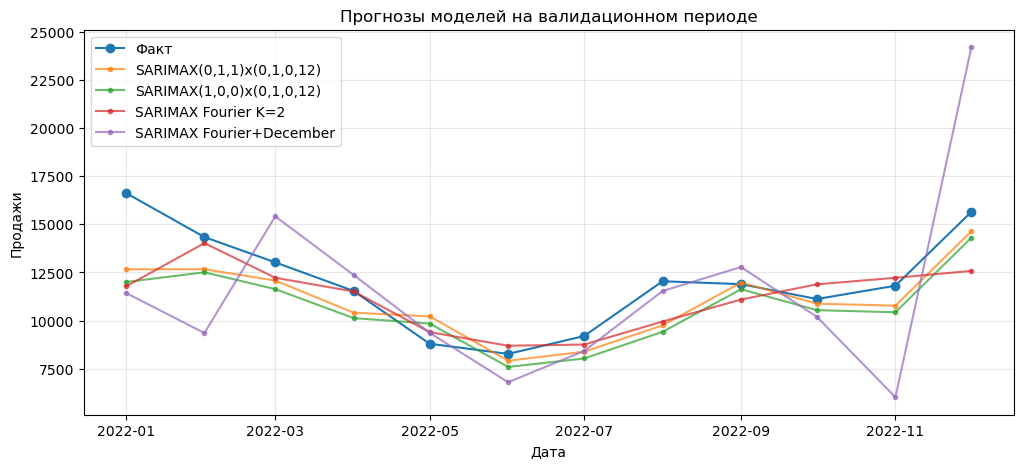

Выбранная модель по минимальной MSE на валидации: SARIMAX(0,1,1)x(0,1,0,12)


In [21]:
valid_results = []
valid_fits = {}
valid_preds = {}

for name in MODEL_CONFIGS.keys():
    try:
        fitted = fit_model(name, train)
        pred, _ = forecast_model(name, fitted, valid.index)

        valid_fits[name] = fitted
        valid_preds[name] = pred

        valid_results.append({
            'Модель': name,
            'MSE validation': mse(valid.values, pred.values),
            'R2 validation': r2(valid.values, pred.values),
            'AIC train': fitted.aic,
            'BIC train': fitted.bic
        })

    except Exception as exc:
        print(f'Модель {name} не обучилась: {type(exc).__name__}: {exc}')

if len(valid_results) == 0:
    raise RuntimeError('Ни одна модель не смогла обучиться на валидационном разбиении.')

valid_df = pd.DataFrame(valid_results).sort_values('MSE validation').reset_index(drop=True)
display(valid_df.round(3))

plt.figure(figsize=(12, 5))
plt.plot(valid.index, valid.values, marker='o', label='Факт')

for name, pred in valid_preds.items():
    plt.plot(pred.index, pred.values, marker='.', alpha=0.7, label=name)

plt.title('Прогнозы моделей на валидационном периоде')
plt.xlabel('Дата')
plt.ylabel('Продажи')
plt.legend()
plt.show()

chosen_name = valid_df.loc[0, 'Модель']
print('Выбранная модель по минимальной MSE на валидации:', chosen_name)


## 8. Проверка моделей на тестовом периоде

Валидация нужна была для выбора модели. Тест нужен для финальной, более честной оценки.

тест не участвует в выборе модели.
модели переобучаются на истории без последнего года.
прогноз делается на последний год.
сравниваются фактические значения и прогнозы.


Модель ARIMA(2,1,1) не обучилась на истории: ValueError: In models with integration (`d > 0`) or seasonal integration (`D > 0`), trend terms of lower order than `d + D` cannot be (as they would be eliminated due to the differencing operation). For example, a constant cannot be included in an ARIMA(1, 1, 1) model, but including a linear trend, which would have the same effect as fitting a constant to the differenced data, is allowed.


,Модель,MSE test,R2 test,AIC history,BIC history
0,"SARIMAX(1,0,0)x(0,1,0,12)",2.500607e+06,0.459,410.738,414.145
1,"SARIMAX(0,1,1)x(0,1,0,12)",2.546563e+06,0.449,382.678,384.767
2,SARIMAX Fourier K=2,3.345446e+06,0.277,611.581,622.469
3,SARIMAX Fourier+December,1.045110e+07,-1.260,683.866,696.309


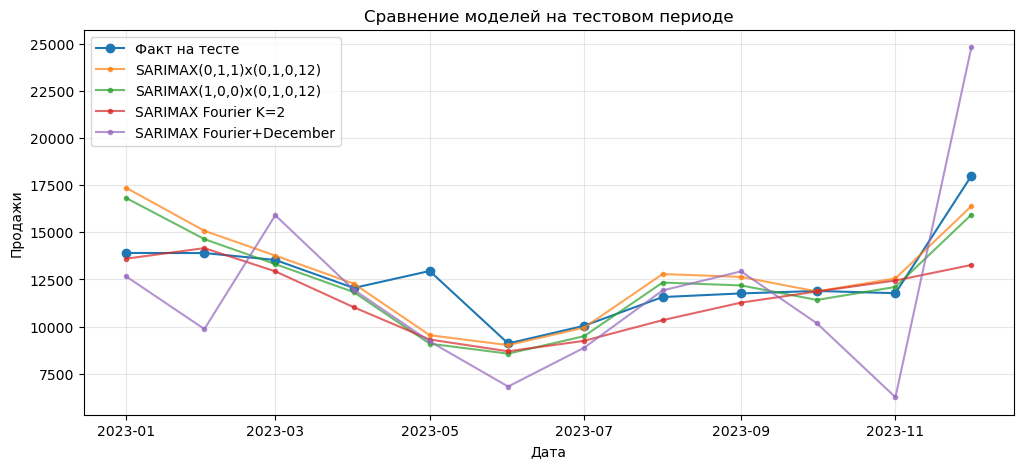

In [22]:
history = y.iloc[:-12]
test = y.iloc[-12:]

test_results = []
test_fits = {}
test_preds = {}
test_intervals = {}

for name in MODEL_CONFIGS.keys():
    try:
        fitted = fit_model(name, history)
        pred, ci = forecast_model(name, fitted, test.index)

        test_fits[name] = fitted
        test_preds[name] = pred
        test_intervals[name] = ci

        test_results.append({
            'Модель': name,
            'MSE test': mse(test.values, pred.values),
            'R2 test': r2(test.values, pred.values),
            'AIC history': fitted.aic,
            'BIC history': fitted.bic
        })

    except Exception as exc:
        print(f'Модель {name} не обучилась на истории: {type(exc).__name__}: {exc}')

if len(test_results) == 0:
    raise RuntimeError('Ни одна модель не смогла обучиться на тестовом разбиении.')

test_df = pd.DataFrame(test_results).sort_values('MSE test').reset_index(drop=True)
display(test_df.round(3))

plt.figure(figsize=(12, 5))
plt.plot(test.index, test.values, marker='o', label='Факт на тесте')

for name, pred in test_preds.items():
    plt.plot(pred.index, pred.values, marker='.', alpha=0.7, label=name)

plt.title('Сравнение моделей на тестовом периоде')
plt.xlabel('Дата')
plt.ylabel('Продажи')
plt.legend()
plt.show()

if chosen_name not in test_fits:
    chosen_name = test_df.loc[0, 'Модель']
    print('Выбранная модель недоступна на тесте. Берём лучшую по тесту:', chosen_name)


## 9. График выбранной модели на тесте

Здесь показываем не только точечный прогноз, но и 95%-й прогнозный интервал.

- точечный прогноз показывает ожидаемый уровень;
- интервал показывает неопределённость;
- если фактические значения часто попадают в интервал, это говорит о корректности оценки неопределённости.


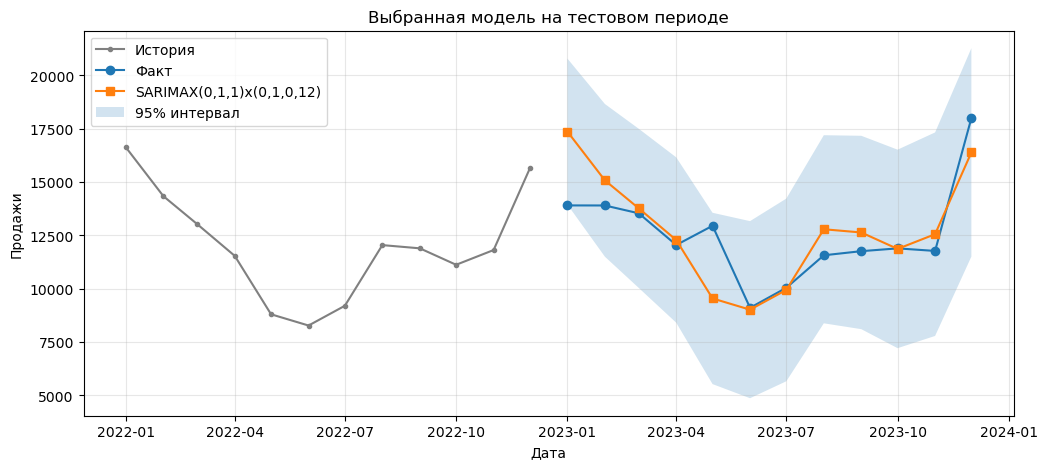

MSE выбранной модели на тесте: 2546563.0
R2 выбранной модели на тесте: 0.449


In [23]:
chosen_pred = test_preds[chosen_name]
chosen_ci = test_intervals[chosen_name]

plt.figure(figsize=(12, 5))
plt.plot(history.iloc[-12:], color='gray', marker='.', label='История')
plt.plot(test.index, test.values, marker='o', label='Факт')
plt.plot(chosen_pred.index, chosen_pred.values, marker='s', label=chosen_name)
plt.fill_between(chosen_ci.index, chosen_ci['lower'], chosen_ci['upper'], alpha=0.2, label='95% интервал')

plt.title('Выбранная модель на тестовом периоде')
plt.xlabel('Дата')
plt.ylabel('Продажи')
plt.legend()
plt.show()

print('MSE выбранной модели на тесте:', round(mse(test.values, chosen_pred.values), 1))
print('R2 выбранной модели на тесте:', round(r2(test.values, chosen_pred.values), 3))


## 10. Диагностика остатков выбранной модели

Нужно проверить, что модель адекватна статистически.
Проверяем остатки:

1. Нормальность — тест Шапиро-Уилка.
2. Автокорреляцию — тест Льюнга-Бокса.
3. Гомоскедастичность — тест Бройша-Пагана.
4. Наличие ARCH-эффектов — тест на условную гетероскедастичность.

Интерпретация:

- если `p-value < 0.05`, соответствующую нулевую гипотезу отвергаем;
- если `p-value >= 0.05`, говорим аккуратно: «нет оснований отвергнуть нулевую гипотезу», а не «гипотеза доказана».


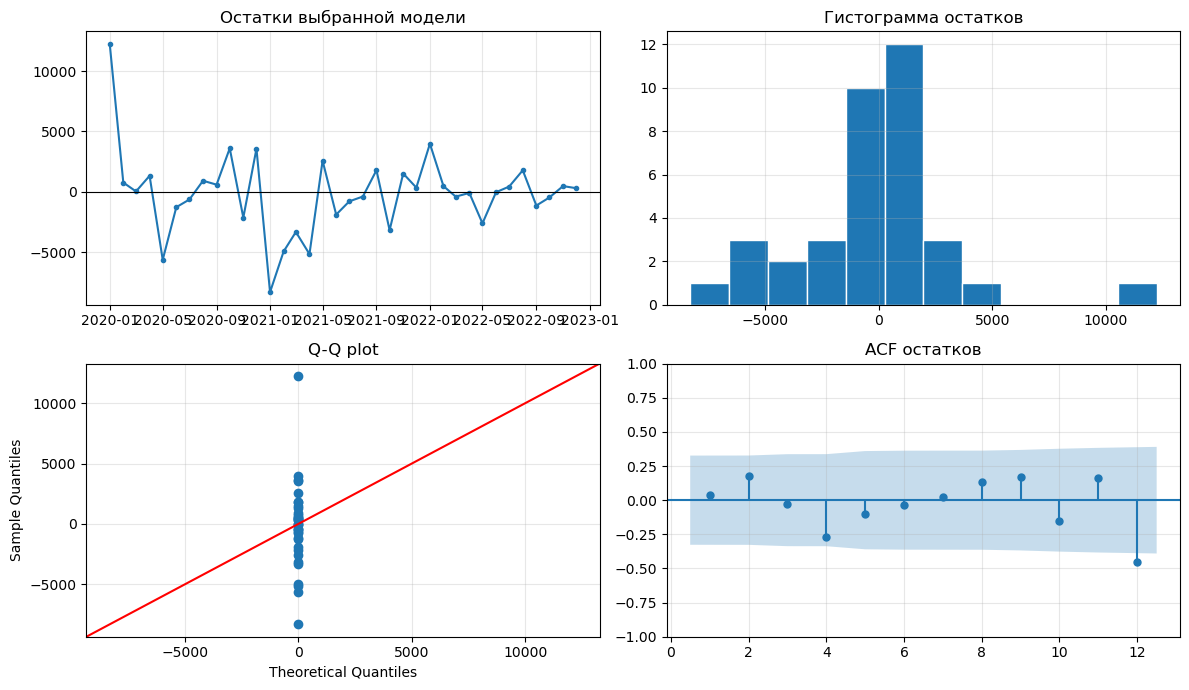

,Проверка,p-value,Вывод при α=0.05
0,Нормальность (Shapiro),0.0032,отклоняем H0
1,"Автокорреляция, лаг 6 (Ljung-Box)",0.5531,нет оснований отклонить H0
2,"Автокорреляция, лаг 12 (Ljung-Box)",0.0426,отклоняем H0
3,Гомоскедастичность (Breusch-Pagan),0.0458,отклоняем H0
4,ARCH-эффекты,0.2685,нет оснований отклонить H0


In [24]:
chosen_fit_history = test_fits[chosen_name]

resid = pd.Series(
    np.asarray(chosen_fit_history.resid),
    index=history.index[-len(chosen_fit_history.resid):]
)

fitted_values = pd.Series(
    np.asarray(chosen_fit_history.fittedvalues),
    index=history.index[-len(chosen_fit_history.fittedvalues):]
)

resid = resid.dropna()
fitted_values = fitted_values.loc[resid.index]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

axes[0, 0].plot(resid.index, resid.values, marker='o', ms=3)
axes[0, 0].axhline(0, color='black', linewidth=0.8)
axes[0, 0].set_title('Остатки выбранной модели')

axes[0, 1].hist(resid.values, bins=12, edgecolor='white')
axes[0, 1].set_title('Гистограмма остатков')

sm.qqplot(resid.values, line='45', ax=axes[1, 0])
axes[1, 0].set_title('Q-Q plot')

plot_acf(resid.values, lags=12, ax=axes[1, 1], zero=False)
axes[1, 1].set_title('ACF остатков')

plt.tight_layout()
plt.show()

shapiro_p = stats.shapiro(resid.values).pvalue

lb = acorr_ljungbox(resid.values, lags=[6, 12], return_df=True)

X_bp = sm.add_constant(np.column_stack([
    fitted_values.values,
    np.arange(len(resid))
]))

bp_p = het_breuschpagan(resid.values, X_bp)[1]
arch_p = het_arch(resid.values, nlags=min(6, max(1, len(resid) // 4)))[1]

diag = pd.DataFrame({
    'Проверка': [
        'Нормальность (Shapiro)',
        'Автокорреляция, лаг 6 (Ljung-Box)',
        'Автокорреляция, лаг 12 (Ljung-Box)',
        'Гомоскедастичность (Breusch-Pagan)',
        'ARCH-эффекты'
    ],
    'p-value': [
        shapiro_p,
        float(lb.loc[6, 'lb_pvalue']),
        float(lb.loc[12, 'lb_pvalue']),
        bp_p,
        arch_p
    ]
})

diag['Вывод при α=0.05'] = np.where(
    diag['p-value'] < 0.05,
    'отклоняем H0',
    'нет оснований отклонить H0'
)

display(diag.round(4))


### Вывод по диагностике остатков

Если автокорреляция не обнаружена, это говорит о том, что модель забрала основную регулярную структуру ряда.

Если нормальность отвергается, это не всегда критично для точечного прогноза, но влияет на интервальное оценивание.

Если обнаруживается гетероскедастичность, можно обсуждать переход к моделям с учётом изменяющейся дисперсии или преобразование ряда.


## 11. Финальный прогноз на 12 месяцев

После проверки модели на тестовом периоде переобучаем выбранную модель уже на всех доступных данных и строим прогноз на следующие 12 месяцев.

1. Сначала доказываем, что модель умеет прогнозировать будущее на исторических данных.
2. Затем используем все доступные наблюдения, чтобы дать финальный прогноз.


,Прогноз,Нижняя граница 95%,Верхняя граница 95%
2024-01-01,14741.2,11214.5,18268.0
2024-02-01,14738.2,11124.1,18352.3
2024-03-01,14371.2,10671.8,18070.6
2024-04-01,12885.2,9102.5,16668.0
2024-05-01,13786.2,9921.9,17650.6
2024-06-01,9941.2,5997.0,13885.5
2024-07-01,10879.2,6856.7,14901.8
2024-08-01,12403.2,8303.9,16502.6
2024-09-01,12596.2,8421.5,16771.0
2024-10-01,12727.2,8478.4,16976.1


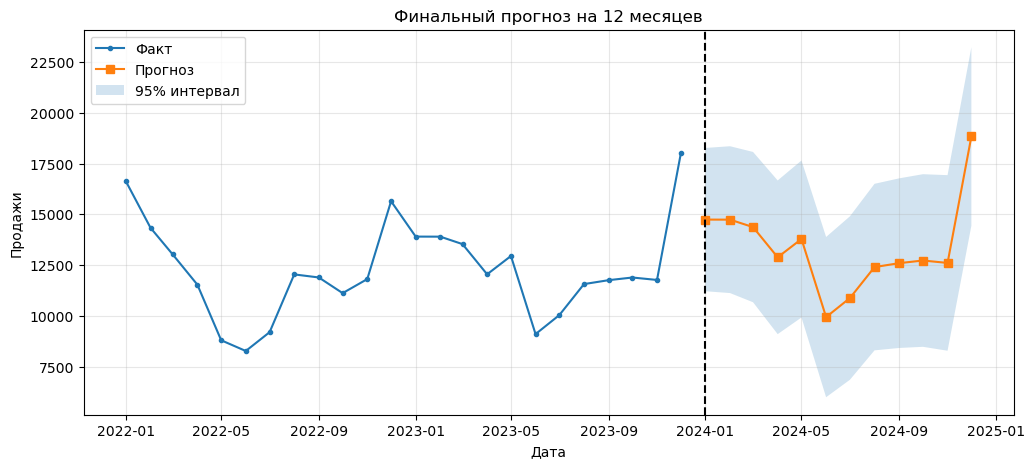

In [25]:
future_index = pd.date_range(
    start=y.index[-1] + pd.DateOffset(months=1),
    periods=12,
    freq='MS'
)

final_fit = fit_model(chosen_name, y)
future_pred, future_ci = forecast_model(chosen_name, final_fit, future_index)

future_table = pd.DataFrame({
    'Прогноз': future_pred.values,
    'Нижняя граница 95%': future_ci['lower'].values,
    'Верхняя граница 95%': future_ci['upper'].values
}, index=future_index)

display(future_table.round(1))

plt.figure(figsize=(12, 5))
plt.plot(y.iloc[-24:], marker='o', ms=3, label='Факт')
plt.plot(future_pred.index, future_pred.values, marker='s', label='Прогноз')
plt.fill_between(
    future_ci.index,
    future_ci['lower'],
    future_ci['upper'],
    alpha=0.2,
    label='95% интервал'
)
plt.axvline(future_index[0], color='black', linestyle='--')

plt.title('Финальный прогноз на 12 месяцев')
plt.xlabel('Дата')
plt.ylabel('Продажи')
plt.legend()
plt.show()


## 12. Итоговая таблица качества моделей

- модель выбиралась не по одному случайному графику;
- использовались разные метрики;
- проверялась не только ошибка прогноза, но и адекватность остатков;
- сравнение моделей выполнялось на одинаковых периодах.


In [26]:
print('Итоговая выбранная модель:', chosen_name)

summary = test_df[test_df['Модель'] == chosen_name][[
    'Модель',
    'MSE test',
    'R2 test',
    'AIC history',
    'BIC history'
]]

display(summary.round(3))


Итоговая выбранная модель: SARIMAX(0,1,1)x(0,1,0,12)


,Модель,MSE test,R2 test,AIC history,BIC history
1,"SARIMAX(0,1,1)x(0,1,0,12)",2546562.972,0.449,382.678,384.767


## 13. Общие выводы по лабораторной работе

1. Был выполнен разведочный анализ временного ряда: проверены пропуски, дубликаты, частота данных, тренд, сезонность и стационарность.
2. Декомпозиция показала структурные компоненты ряда: тренд, сезонность и остаток.
3. `FFT` позволил проверить наличие годовой периодичности около 12 месяцев.
4. Вейвлет Морле позволил увидеть, как эта периодичность проявляется во времени.
5. Для прогнозирования использовались модели `ARIMA` и несколько вариантов `SARIMAX`.
6. Модели сравнивались по `MSE`, `R²`, `AIC`, `BIC`.
7. Остатки выбранной модели проверены на нормальность, автокорреляцию, гомоскедастичность и ARCH-эффекты.
8. Финальный прогноз построен на 12 месяцев вперёд с доверительным интервалом.

